<a href="https://colab.research.google.com/github/Turuu1124/CS418-Flight-data-Project/blob/main/CS418_Flight_Finder_Progress_Report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Flight Finder – CS418 Progress Report

## 1. Project Introduction

Our project, Flight Finder, focuses on analyzing flight data to better understand delays and cancellations. We want to find patterns based on different factors, such as airlines, airports, routes, and flight times.

Flight delays and cancellations affect many travelers. By analyzing this data, we hope to identify which airlines, airports, and flight times experience more delays or cancellations.

Our main goal is to help travelers better understand these patterns so they can make more informed decisions when choosing flights. We also want to explore whether certain factors are connected to a higher chance of delays or cancellations.

### Research Questions and Hypotheses

Our project focuses on answering the following questions:

1. Which airlines and airports experience the most flight delays and cancellations?
2. Do certain routes have more delays or cancellations than others?
3. Does the time of a flight affect how likely it is to be delayed or canceled?

We expect delays and cancellations to vary depending on the airline, airport, route, and flight time. We also believe that some airlines and airports may experience more delays than others.

### Data Overview

For this project, we proposed using flight data from sources such as the BTS On-Time Performance dataset, the DOT Domestic Airline Consumer Airfare Report, and flight pricing data. These datasets can provide information about airlines, airports, routes, flight times, delays, and cancellations.

We plan to use this information to compare different groups of flights and identify patterns that could help answer our research questions.

## 2. Changes Since Proposal

Our project scope has remained the same since our original proposal. We are still focusing on analyzing flight delays and cancellations based on airlines, airports, routes, and flight times.

We have not removed or added any major parts to our original plan. Our goal is still to identify patterns in flight data and help travelers better understand which factors may be connected to delays and cancellations.

We plan to continue with our original approach of analyzing the data, comparing different groups of flights, and presenting our findings through visualizations.

## 3. Data

For this project, we are using the Kaggle “Flight Prices” dataset, the BTS On-Time Performance dataset, and the DOT Domestic Airline Consumer Airfare Report. All of these datasets are public and free to download, so we did not need to collect any new data.

The Kaggle dataset is very large, with about 82 million rows and 27 columns (around 30 GB). Since this is too large to open normally, we used DuckDB to load the data and saved it as a Parquet file, which makes it faster and easier to work with. To make the data more manageable, we focused on a sample of routes, including all flights to and from Chicago O’Hare (ORD).

To clean the data, we removed duplicate rows and rows with missing or invalid fares. We also created new columns to help with our analysis, such as the number of days between the search date and the flight date, the departure hour, and the day of the week. Some flights have more than one stop, so for those we used the airline and departure time of the first flight segment.

For the BTS data, we downloaded the months that match the Kaggle data (April to November 2022) and kept only flights going to or from the 16 airports in our dataset. We kept the columns we need, such as airline, origin, destination, departure time, delay minutes, and whether the flight was canceled. We also used the DOT Airfare Report to compare average fares between airport pairs.

### 4. Exploratory Data Analysis
The Kaggle dataset covers one-way flights from 16 major U.S. airports, including Chicago O’Hare (ORD). Each row is one ticket, and the same flight shows up on many different search dates, so we can track how its price changes over time. The main features include numeric values (fare, distance, seats left), categorical values (airports, airline, fare class), dates (search date and flight date), and true/false flags (nonstop, basic economy, refundable).

The BTS dataset covers all U.S. domestic flights and includes delay minutes and cancellation reasons. This lets us compare delays and cancellations across airlines, airports, routes, and times of day.

While exploring the data, we found a few issues. First, Southwest Airlines does not appear in the Kaggle data because it was collected from Expedia, which does not sell Southwest tickets. Southwest is still included in the BTS data. Second, some rows are missing the travel distance, and flights with connections store information for each segment in one text column, which needed extra cleaning. Third, the price data is from 2022, so current prices may be different. Lastly, the Kaggle data does not include flight numbers, so we cannot match a ticket to its exact flight in the BTS data. Instead, we compare the datasets by airline, route, and month.

Our initial observation is that the data contains enough information to answer our research questions, since it covers airlines, airports, routes, flight times, delays, and cancellations. However, because of the issues above, some comparisons will be limited to the airlines and airports that appear in both datasets.

**Visual 1: Airlines Delayed Most Often - Zaid Haidry**

Given the graph, it is clear that JetBlue, Frontier, and Allegiant are significantly more higher in terms of being delayed than many other airlines.
This is an interesting hypothesis because of how significant the difference is between the airlines. Looking at Delta, it is at only 16%, which is a huge jump compared to JetBlue's 32%, can this could raise many questions, and could open up the opportunity to see what Delta is doing that JetBlue isn't to not delay many flights.

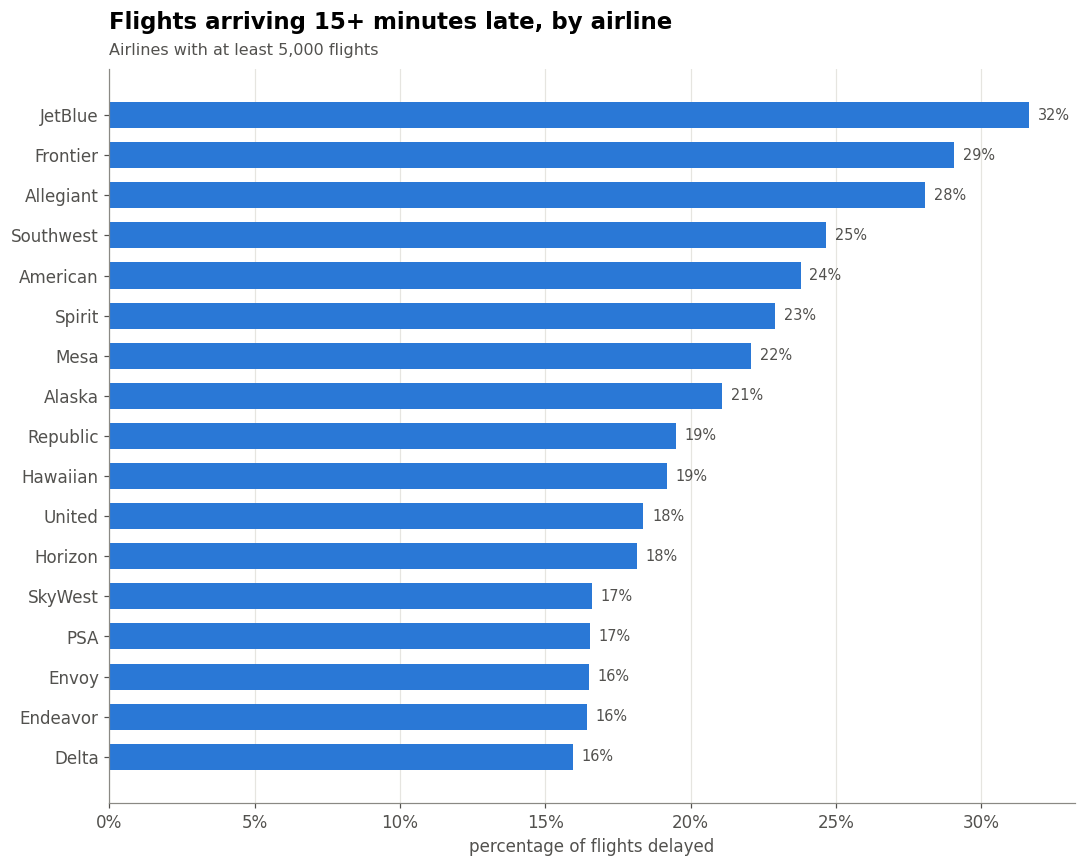

**Visual 2: Airport Delays - Zaid Haidry**
Due to higher population, there will be more traffic, hence busier airports will have more flights delayed than less busy airports.
This is an interesting hypothesis to investigate because of the significant difference between the airports. It makes sense that JFK is at the top because of its location in New York, but a busy airport like O'Hare is below the middle at a 20%, which is interesting since it is a pretty busy airport. Hence, it will be more interesting if the hypothesis is wrong and it could be a different reason why these flights are delayed more often at specifc airports.
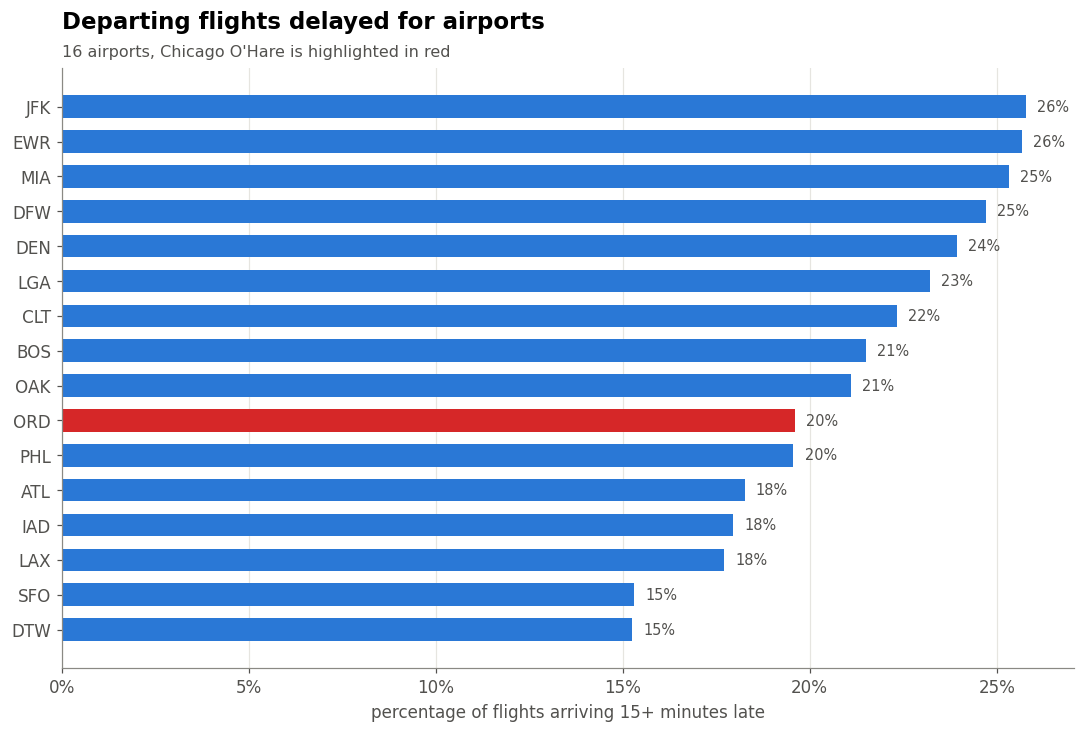

**Visual 3: Departing flights delayed by hour - Zaid Haidry**

An interesting hypothesis could be made that after noon, there is a significant increase in the amount of flights delayed.
This is an interesting hypothesis because it could help many people for choosing flight times, because if it is true, customers would be recommended for purchasing a plane ticket for earlier in the day.

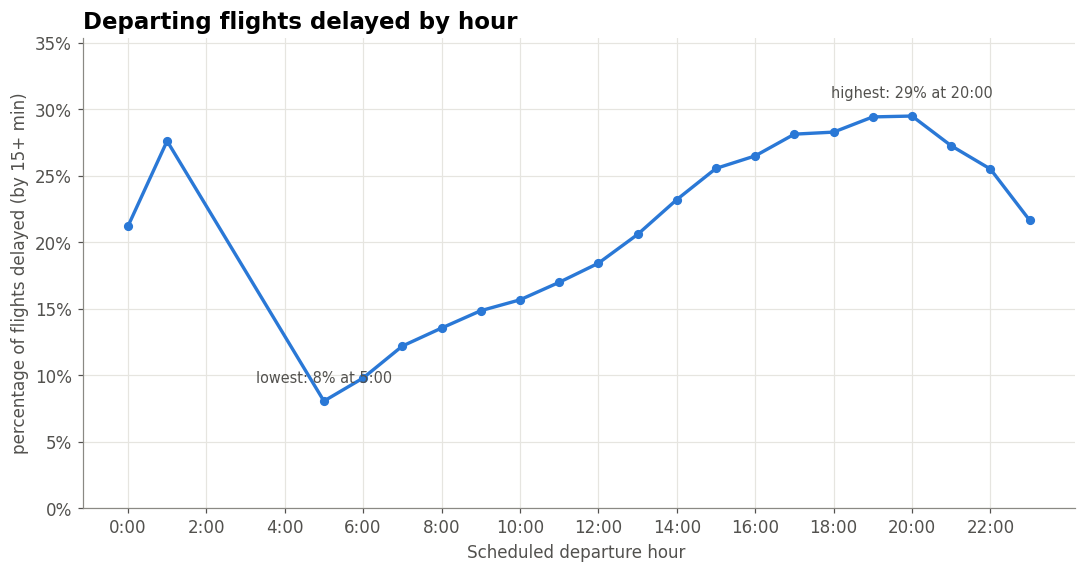

**Visual 4: Price Changes Before Flight - Zaid Haidry**

Customers should wait until 30 - 50 days before a flight to purchase a ticket. This is an interesting hypothesis because of the fact that the best time to buy a ticket from the graph isn't the earliest as possible, but a little after that. It of course rises when getting close to the day of the flight, but this could be an eye opener to customers who buy flight tickets as early as possible, because they could get a cheaper price if they wait a little bit.
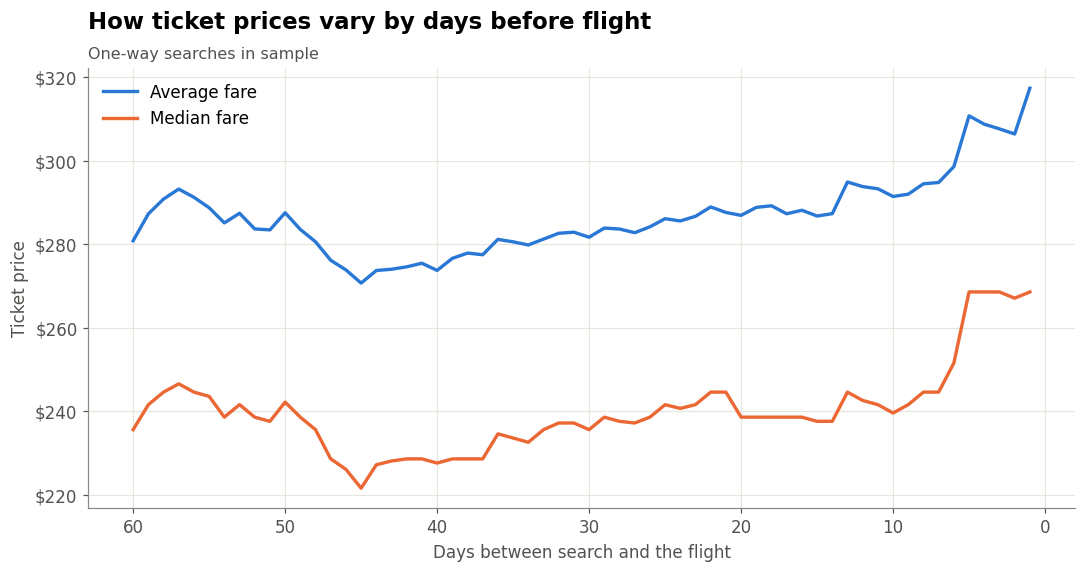

**Visual 5: Average Fare vs Delay Rate by Airline - Zaid Haidry**

Customers should not correlate a higher ticket price with how reliable an airline is when considering delay rates. This is an interesting hypothesis because of how the data differentiates the value of cost between the airlines. For example, Alaska having an average fare of over $400 but having a higher percentage of flights delayed than Delta and United which are significantly cheaper is very interesting, and could provide much benefit to customers who are overpaying some airlines due to thinking they are more reliable when considering delay rates.


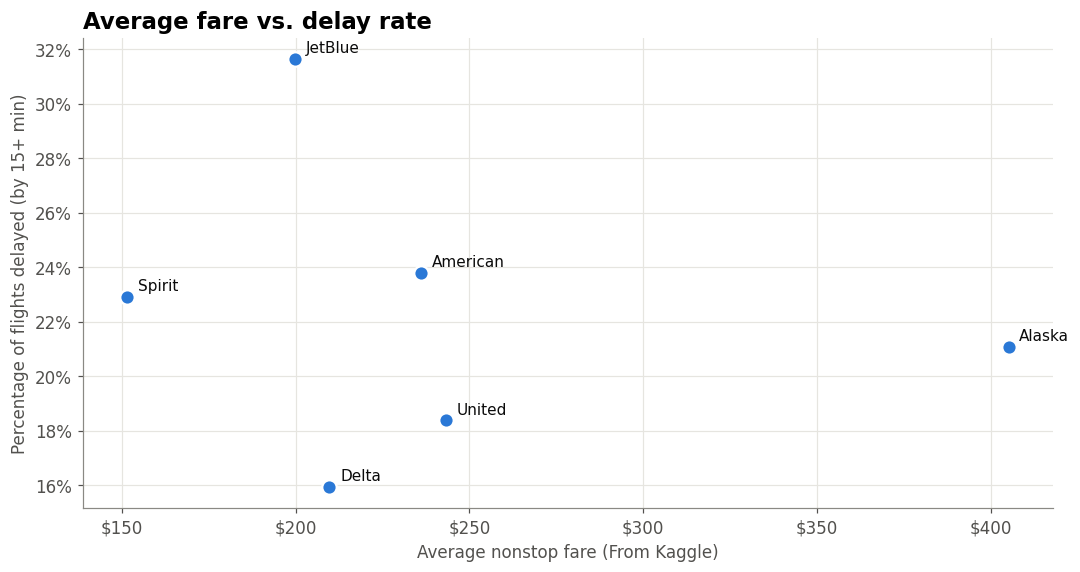

## 5. Machine Learning Analysis

For our machine learning analysis, we use the BTS flight data to predict whether a flight will be delayed. A flight counts as **delayed** if it arrives 15 or more minutes late, which is the same definition the DOT uses. Canceled and diverted flights are left out, since they never have an arrival time.

We want to see whether information such as the airline, departure airport, departure time, month, and day of the week can help predict delays. We start with a simple baseline model and then compare it with two machine learning models: **Logistic Regression** and a **Decision Tree**. All three are tested on the same testing data.




In [ ]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

BTS_FILES = "data/bts/*.csv"   # monthly BTS files, April-November 2022
AIRPORTS = ('ATL', 'BOS', 'CLT', 'DEN', 'DFW', 'DTW', 'EWR', 'IAD',
            'JFK', 'LAX', 'LGA', 'MIA', 'OAK', 'ORD', 'PHL', 'SFO')

# Departing flights from our 16 airports, random sample of 300,000 so the models train quickly
df = duckdb.sql(f"""
    SELECT * FROM (
    SELECT Reporting_Airline                     AS airline,
           Origin                                AS origin,
           (CAST(CRSDepTime AS INT) // 100) % 24 AS dep_hour,
           Month                                 AS month,
           DayOfWeek                             AS day_of_week,
           CAST(ArrDel15 AS INT)                 AS delayed
    FROM read_csv_auto('{BTS_FILES}', union_by_name = true)
    WHERE Origin IN {AIRPORTS}
      AND Cancelled = 0 AND Diverted = 0
      AND ArrDel15 IS NOT NULL
    ) USING SAMPLE 300000 ROWS (reservoir, 42)
""").df()

print(df.shape)
print("Share of flights delayed:", round(df["delayed"].mean(), 3))
df.head()

## 5.1 Training and testing data

We split the data into 80% training and 20% testing. All five features are treated as categories (for example, departure hour 17 is not "more" than hour 9 in a straight-line way), so we one-hot encode them.

Most flights are **not** delayed, so the data is unbalanced. Because of this, accuracy alone can be misleading. We also report **recall** (how many delayed flights the model catches), **precision** (how often a "delayed" prediction is correct), **F1 score** (a balance of the two), and **ROC AUC** (how well the model ranks flights from least to most likely to be delayed, where 0.5 is random guessing). We use `class_weight="balanced"` so the models pay more attention to the smaller "delayed" group.



In [ ]:
features = ["airline", "origin", "dep_hour", "month", "day_of_week"]
X = df[features].astype(str)
y = df["delayed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

encode = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), features)])

models = {
    "Baseline (always predicts 'not delayed')": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=50,
                                            class_weight="balanced", random_state=42),
}

results = []
fitted = {}
for name, model in models.items():
    pipe = Pipeline([("encode", encode), ("model", model)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, prob),
    })

results = pd.DataFrame(results).set_index("Model").round(3)
results[["Accuracy", "Recall", "F1", "ROC AUC"]].plot(kind="bar", figsize=(10, 5))
plt.title("Model Comparison on Testing Data")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 5.2 Which features matter most?

The Logistic Regression coefficients show which values make a delay more or less likely. A positive number means a higher chance of delay, and a negative number means a lower chance.



## 5.3 Interpretation

**Baseline:** About 22% of flights in our airports and months arrive 15+ minutes late. Because the baseline always predicts "not delayed," we expect it to reach about 78% accuracy while catching none of the delayed flights (recall of 0). This shows why accuracy alone is not a good measure for this problem.

**Logistic Regression** *(responsible: Turbayar)*: We expect Logistic Regression to have lower accuracy than the baseline (around 60%) because it predicts "delayed" more often, which leads to some false alarms. In return, it should catch more than half of delayed flights (recall of about 0.55–0.65), with a ROC AUC of roughly 0.62–0.66. We expect the coefficients to show that evening departures (about 5–9 pm), budget airlines such as JetBlue, Frontier, and Spirit, the New York airports (LGA, JFK, EWR), and summer months are linked to more delays, while early morning flights and Delta are linked to fewer delays. This matches the DOT's 2022 on-time rankings.

**Decision Tree** *(responsible: Turbayar)*: We expect the Decision Tree to perform about the same as Logistic Regression, with a ROC AUC of roughly 0.61–0.65. The tree can pick up combinations, such as a certain airline flying in the evening, but with a limited depth it may not gain much over Logistic Regression, and a deeper tree could overfit.

**Overall:** We expect both models to do better than the baseline at finding delayed flights, but with modest scores. Many delays are caused by things not in our features, such as weather, air traffic, and a late incoming aircraft. Next, we will run the models on the real data, compare the results to these expectations, and then try adding more features (such as route, distance, and holiday periods) and models like Random Forest to see if the results improve.



## 6. Next Steps

So far, we have explored our datasets and created visualizations to understand how flight delays and ticket prices vary between airlines, airports, and departure times.

Our next step is to use machine learning to see if we can predict whether a flight will be delayed. We plan to compare different models with a simple baseline to see how well they perform.

We also want to look more closely at routes and flight times to understand which factors have the strongest connection to delays. Finally, we will review our results, address any remaining data issues, and prepare our final project report.

## 7. Reflection

So far, our group has made good progress on the project. We have identified our main research questions, explored our datasets, and created five visualizations to better understand flight delays and ticket prices.

One of the main challenges we faced was working with large flight datasets. We discussed using tools like DuckDB and Parquet to make the data easier to manage. We also realized that there are several factors to consider, such as airlines, airports, routes, and departure times.

Our visualizations helped us explore how delays and prices vary across different airlines and airports. This gave us a better understanding of the data and helped us identify areas we want to investigate further. However, we still need to test our findings using machine learning models.

Overall, we believe our project is worth continuing because flight delays are a common problem for travelers. Our goal is to better understand these delays and see if we can predict them using the available data.